# Audit, analisis LDA tervalidasi, dan eksperimen wisata — v2

**Malik Hariyanto · Asistensi Hibah Penelitian**

Dataset dimuat otomatis; jalankan sel berurutan. Versi ini memisahkan train/validation/test per destinasi, membandingkan jumlah topik dan seed, menampilkan contoh ulasan, serta memilih checkpoint BiLSTM berdasarkan validation loss.

**Landasan setiap keputusan dan parameter:** [METODOLOGI_DAN_PAPER.md](https://github.com/MalikHariyanto/crispy_recom_machine_system/blob/research/audit-wisata-madura/docs/METODOLOGI_DAN_PAPER.md). ID R01–R14 di bawah merujuk daftar tersebut. Nilai hiperparameter adalah pengaturan eksperimen, bukan angka yang diklaim diwajibkan paper.

Data mencakup wilayah campuran, dua atribut destinasi, serta tanggal relatif. Topik belum merupakan aspek/sentimen tervalidasi. Notebook ini tidak mengimplementasikan fusion BGE-E5 pada sertifikat HKI.

## 00 Konfigurasi dan instalasi

Biarkan `DATA_PATH = None`: tidak perlu upload dataset. `RUN_DEEP=True` melatih dua BiLSTM; GPU disarankan. `RUN_DEEP=False` tetap menjalankan seluruh analisis LDA, baseline, grafik, dan ekspor.

Pencarian default: 6 jumlah topik × 3 seed = 18 LDA. Semua parameter terlihat di sini; batas komputasi dan alasan pengaturan dijelaskan pada dokumen metodologi. R01–R05, R07–R13.

In [1]:
from datetime import datetime
from pathlib import Path

DATA_PATH = None
REGION_PATH = None
OUTPUT_DIR = Path("hasil_wisata_madura") / datetime.now().strftime("%Y%m%d-%H%M%S-%f")
JUDGMENTS_PATH = None
SEED = 42
VALIDATION_SEED = 142
TEST_FRACTION = 0.20
VALIDATION_FRACTION = 0.20  # Dari sisa train; tidak mengubah test awal.
TOPIC_COUNTS = (2, 4, 6, 8, 10, 12)
LDA_SEEDS = (42, 43, 44)
LDA_MAX_ITER = 20
LDA_REVIEWS_PER_DESTINATION = 30
RUN_DEEP = True
RUN_BGE = False
MAX_BILSTM_EPOCHS = 15
EARLY_STOPPING_PATIENCE = 3

In [2]:
import subprocess
import sys
import os
import hashlib

cwd = Path.cwd()
checkout = cwd / "wisata_madura_lda_v2"
candidates = (cwd, cwd.parent, checkout)
repo_root = next((p for p in candidates if
    (p / "src" / "wisata_madura" / "topics.py").is_file()
    and (p / "data" / "manifest.json").is_file()), None)
if repo_root is None:
    if checkout.exists():
        raise FileExistsError(f"{checkout} belum memuat v2. Ganti nama folder lama, lalu ulangi sel ini.")
    subprocess.run(["git", "clone", "--depth", "1", "--branch", "research/audit-wisata-madura",
                    "https://github.com/MalikHariyanto/crispy_recom_machine_system.git", str(checkout)], check=True)
    repo_root = checkout
requirements = ["-r", str(repo_root / "requirements-wisata.txt")]
if RUN_DEEP:
    requirements += ["gensim>=4.4,<5", "torch>=2.2,<3"]
if RUN_BGE:
    requirements += ["sentence-transformers>=3,<6"]
subprocess.run([sys.executable, "-m", "pip", "install", "--disable-pip-version-check", *requirements], check=True)
# Kernel yang sudah mengimpor modul versi lama harus direstart, agar hasil tidak mencampur versi.
if any(name.startswith("wisata_madura") for name in sys.modules):
    raise RuntimeError("Modul sudah pernah diimpor. Restart runtime/kernel dan jalankan dari awal.")
sys.path.insert(0, str(repo_root / "src"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str((OUTPUT_DIR / ".matplotlib").resolve()))
source_files = list((repo_root / "src" / "wisata_madura").glob("*.py"))
source_hashes = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in source_files}
source_commit = subprocess.check_output(["git", "-C", str(repo_root), "rev-parse", "HEAD"], text=True).strip() if (repo_root / ".git").exists() else "zip_snapshot; see source hashes"
print("Source:", source_commit)

Source: 3adb62eed2fc3c99ca08a06dffa22900b08d2414


## 01 Muat dataset otomatis dan periksa skema

**Masukan:** paket di folder `data/`, dibentuk dari lembar **Data Ulasan** pada `koreksi_dataset.xlsx`. Kode memeriksa checksum, jumlah baris, dan konsistensi label sebelum data masuk ke model. Untuk cakupan Madura, isi kabupaten pada templat CSV dan pasang `REGION_PATH`. Baris dengan kabupaten kosong dianggap belum terverifikasi. Tanpa CSV, keluaran mendeskripsikan workbook campuran.

Paket memuat teks model dari kolom `text_preprocessed`, nama dan ID destinasi, label, serta penanda audit. Teks asli, rating, dan nilai tanggal Excel tidak diperlukan untuk pelatihan. Normalisasi ringan mempertahankan negasi seperti *tidak* atau *kurang*.

In [3]:
import json
from importlib.metadata import version

import pandas as pd
from IPython.display import display

from wisata_madura.data import (
    audit_bundled_reviews, audit_reviews, label_distribution, load_bundled_reviews,
    load_reviews, region_template,
    select_madura_reviews, split_reviews,
)
from wisata_madura.modeling import evaluate_classifiers, fit_topics, run_baselines, run_lda_only

if DATA_PATH is None:
    source_reviews, data_manifest = load_bundled_reviews(repo_root / "data")
    print("Dataset bawaan repo berhasil dimuat.")
else:
    data_manifest = None
    source_reviews = load_reviews(Path(DATA_PATH))
    print(f"Dataset alternatif dimuat dari {DATA_PATH}.")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
region_template(source_reviews).to_csv(OUTPUT_DIR / "template_verifikasi_wilayah.csv", index=False)
if REGION_PATH is None:
    reviews = source_reviews
    geography = {
        "scope": "workbook_complete_unverified",
        "source_destinations": source_reviews["id_destinasi"].nunique(),
    }
    print("Cakupan: workbook campuran. Isi REGION_PATH untuk analisis khusus Madura.")
else:
    reviews, geography = select_madura_reviews(source_reviews, REGION_PATH)
    print("Cakupan: ID destinasi Madura yang telah diverifikasi pada CSV.")
print(f"{len(reviews):,} ulasan dari {reviews['id_destinasi'].nunique()} destinasi")
print(list(reviews.columns))

Dataset bawaan repo berhasil dimuat.
Cakupan: workbook campuran. Isi REGION_PATH untuk analisis khusus Madura.
79,514 ulasan dari 207 destinasi
['id_destinasi', 'destinasi', 'rekomendasi_cuaca', 'wisata', 'teks_model', 'duplikat_persis', 'tanggal_relatif', 'indikasi_encoding', 'teks_asli_kosong', 'teks_olahan_kosong', 'tanggal_kosong', 'rating_kosong']


## 02 Audit kualitas dan distribusi label

**Keluaran:** jumlah teks kosong, duplikat persis, tanggal relatif, indikator karakter rusak, dan distribusi atribut. Indikator karakter rusak membantu memilih sampel untuk diperiksa. Pada paket bawaan, hitungan tanggal relatif dan karakter rusak menggunakan penanda yang dihitung dari workbook sumber.

In [4]:
if data_manifest is None:
    audit = audit_reviews(reviews, Path(DATA_PATH))
else:
    audit = audit_bundled_reviews(reviews, data_manifest)
audit["geography"] = geography
distribution = label_distribution(reviews)
display(pd.Series({key: audit[key] for key in (
    "rows", "destinations", "exact_duplicate_rows", "empty_normalized_text_rows",
    "relative_date_rows", "potential_encoding_error_rows",
)}))
display(distribution)
distribution.to_csv(OUTPUT_DIR / "distribusi_label.csv", index=False)

rows                             79514
destinations                       207
exact_duplicate_rows               631
empty_normalized_text_rows          10
relative_date_rows               79514
potential_encoding_error_rows    14659
dtype: int64

,target,kelas,ulasan,destinasi
0,rekomendasi_cuaca,Kemarau,36590,94
1,rekomendasi_cuaca,Kemarau & Penghujan,42924,113
2,wisata,air terjun,6267,24
3,wisata,danau/waduk,1921,9
4,wisata,desa/kampung wisata,2439,6
5,wisata,goa,2903,8
6,wisata,hutan/perkebunan,6107,14
7,wisata,lainnya,3393,8
8,wisata,pantai,16444,47
9,wisata,pegunungan,8262,22


## 03 Pisahkan train, validation, dan test

R06: evaluasi harus memperhitungkan struktur kelompok data. Test awal tetap sekitar 20% destinasi; validation diambil sekitar 20% dari destinasi train sisanya. Semua model dilatih pada subset train yang sama. ID dan teks identik diperiksa agar tidak berbagi antarpartisi. Rasio ulasan tidak persis 64:16:20 karena ukuran destinasi berbeda.

Validation dipakai memilih jumlah topik dan checkpoint; test hanya untuk evaluasi akhir. Kelas langka bisa tidak muncul pada validation—lihat audit. Hasil v2 tidak langsung sebanding dengan angka v1 yang memakai train lebih besar.

In [5]:
from wisata_madura.data import validation_split
outer_split = split_reviews(reviews, test_fraction=TEST_FRACTION, seed=SEED)
split = validation_split(outer_split, fraction=VALIDATION_FRACTION, seed=VALIDATION_SEED)
audit.update(split.audit)
display(pd.DataFrame({"ulasan": split.audit["partition_reviews"],
                      "destinasi": split.audit["partition_destinations"]}))
print("Kelas tidak hadir pada validation:", split.audit["validation_split"]["classes_absent_from_test"])
for name, frame in (("train", split.train), ("validation", split.validation), ("test", split.test)):
    frame[["id_destinasi", "wisata", "rekomendasi_cuaca"]].drop_duplicates().assign(partisi=name).to_csv(
        OUTPUT_DIR / f"id_partisi_{name}.csv", index=False)

,ulasan,destinasi
train,47459,130
validation,12473,34
test,12849,43


Kelas tidak hadir pada validation: {'rekomendasi_cuaca': [], 'wisata': ['sungai']}


## 04 Latih model pembanding

R14: TF-IDF + Linear SVC dibandingkan dengan kelas mayoritas. Fit hanya train; vocabulary tidak mempelajari validation/test. Partisi train ini sama dengan yang dipakai LDA dan BiLSTM.

In [6]:
predictions = run_baselines(split, seed=SEED)
print("Model pembanding:", list(predictions))

Model pembanding: ['mayoritas', 'tfidf_linear_svc']


## 05A Cari jumlah topik, ukur coherence, perplexity, dan kestabilan

R01–R05: LDA memakai count kata (bukan embedding). Kosakata dan model hanya fit pada sampel train, maksimal 30 ulasan per destinasi. Stopword Indonesia/Inggris eksplisit disimpan di audit; negasi dipertahankan. Ini berlaku untuk LDA, bukan menghapus kata dari masukan FastText/TF-IDF.

Bandingkan K dan seed pada **validation**. Coherence di sini adalah **NPMI per dokumen**, bukan c_v atau NPMI dengan sliding window; pasangan tidak muncul bersama diberi -1. Pilih K dari rerata validation NPMI; jika seri, stability lalu perplexity. Gunakan seed utama yang sudah ditentukan. Stabilitas berupa top-word Jaccard dengan pencocokan topik optimal; ini adaptasi diagnosis, bukan reproduksi lengkap Greene dkk.

Coherence tinggi relatif belum membuktikan aspek bermakna. NPMI negatif/topik tidak stabil perlu dibaca bersama contoh ulasan. Model tidak dilatih ulang pada validation setelah pencarian.

LDA K=2, seed=42: validation NPMI=-0.0870, perplexity=1056.9


LDA K=2, seed=43: validation NPMI=-0.0418, perplexity=1061.7


LDA K=2, seed=44: validation NPMI=-0.0474, perplexity=1044.2


LDA K=4, seed=42: validation NPMI=-0.1848, perplexity=1483.4


LDA K=4, seed=43: validation NPMI=-0.0820, perplexity=1542.7


LDA K=4, seed=44: validation NPMI=-0.0316, perplexity=1484.4


... (12 outputs left out)

Fontconfig error: No writable cache directories


K terpilih: 2


,n_topics,validation_npmi_mean,validation_npmi_std,validation_perplexity_mean,topic_diversity_mean,stability_jaccard
0,2,-0.0587,0.0246,1054.2928,0.9333,0.6600
1,4,-0.0995,0.0781,1503.4995,0.8917,0.3134
2,6,-0.2286,0.0348,1842.2869,0.8778,0.2332
3,8,-0.2936,0.0185,2105.5826,0.9000,0.2164
4,10,-0.3229,0.0344,2359.6932,0.8767,0.2024
5,12,-0.3324,0.0197,2584.0624,0.9000,0.1905


,topik,kata_utama,validation_npmi,rata_rata_bobot_train,dokumen_dominan_train
0,topik_1,"wisata, candi, sejarah, kunjung, satu, alam, t...",-0.2443,0.3776,1300
1,topik_2,"tempat, bagus, pantai, banyak, jalan, bersih, ...",0.0703,0.6224,2499


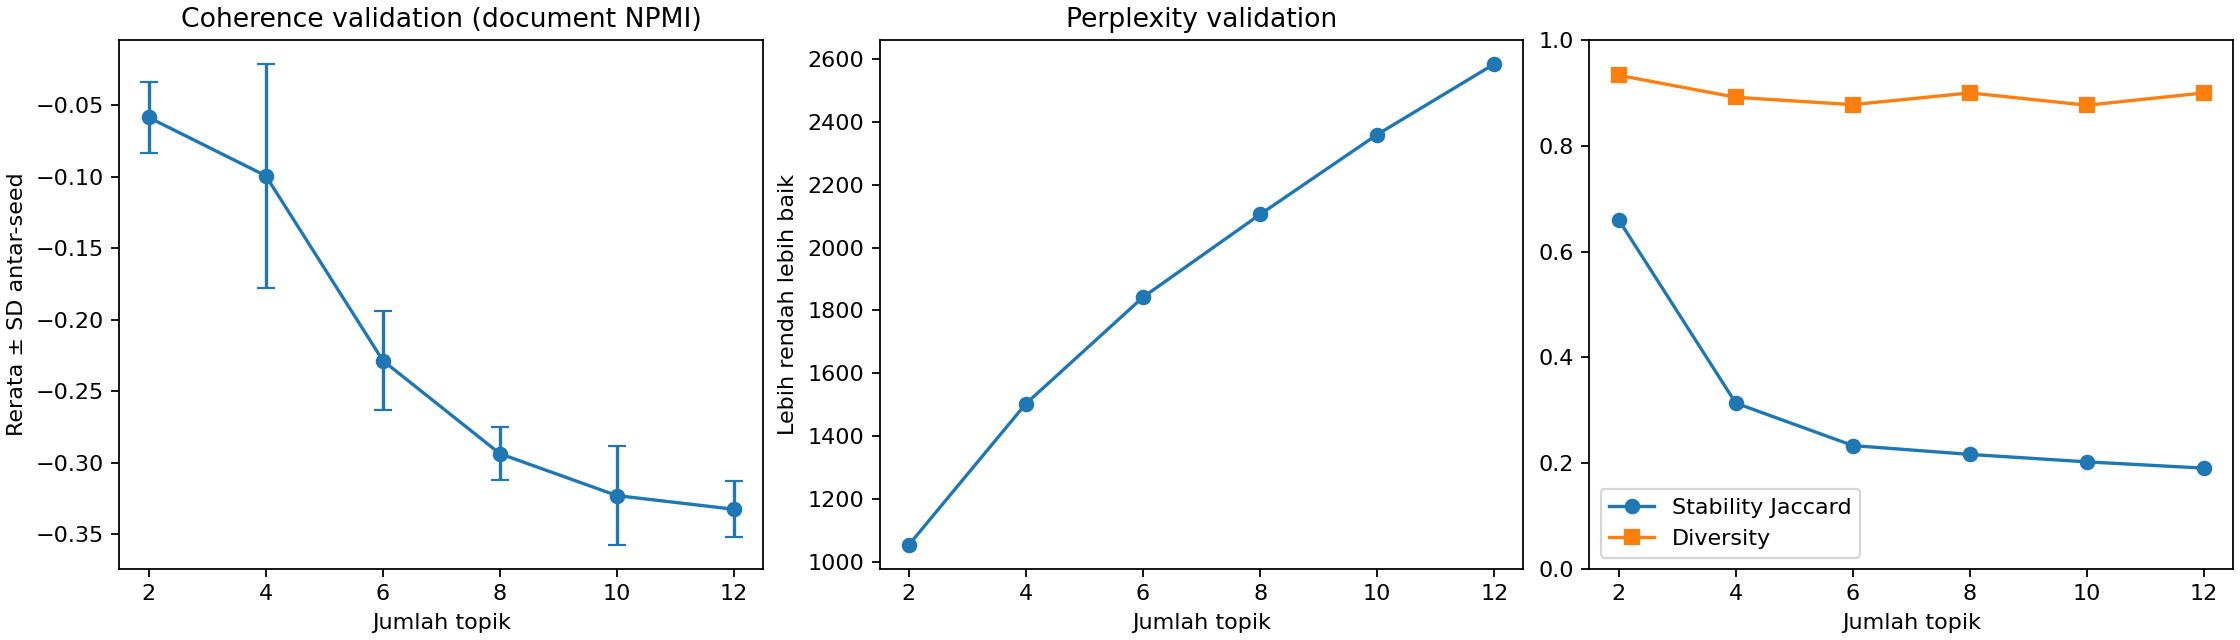

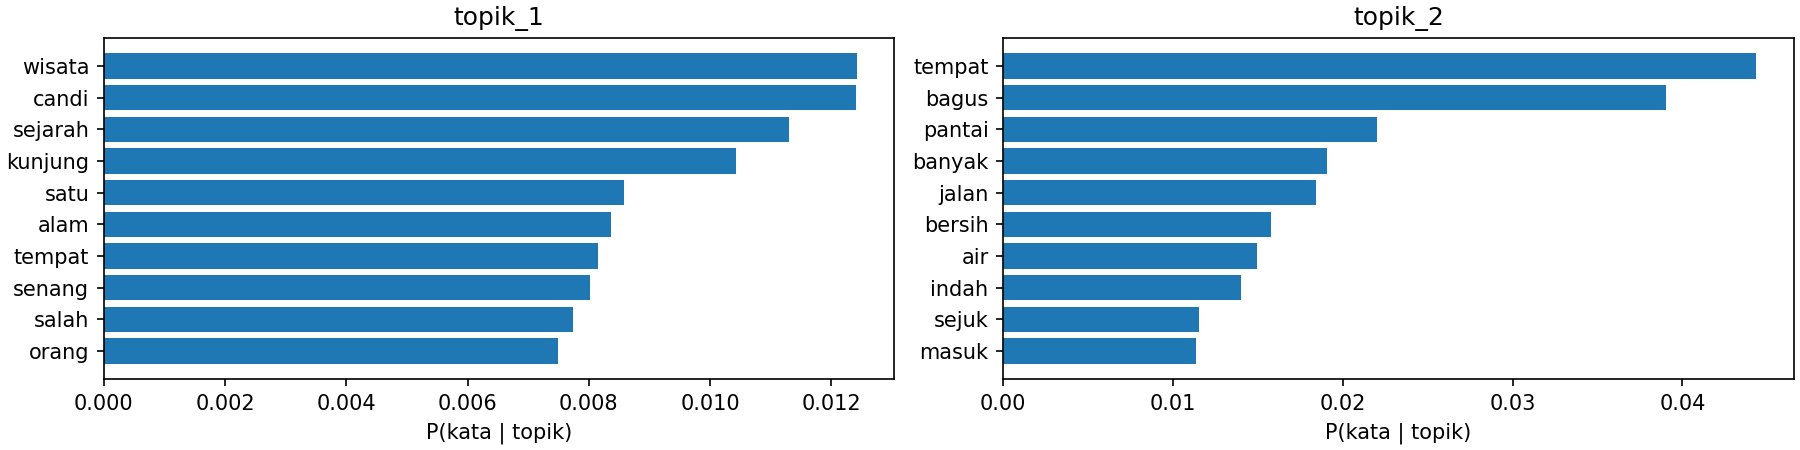

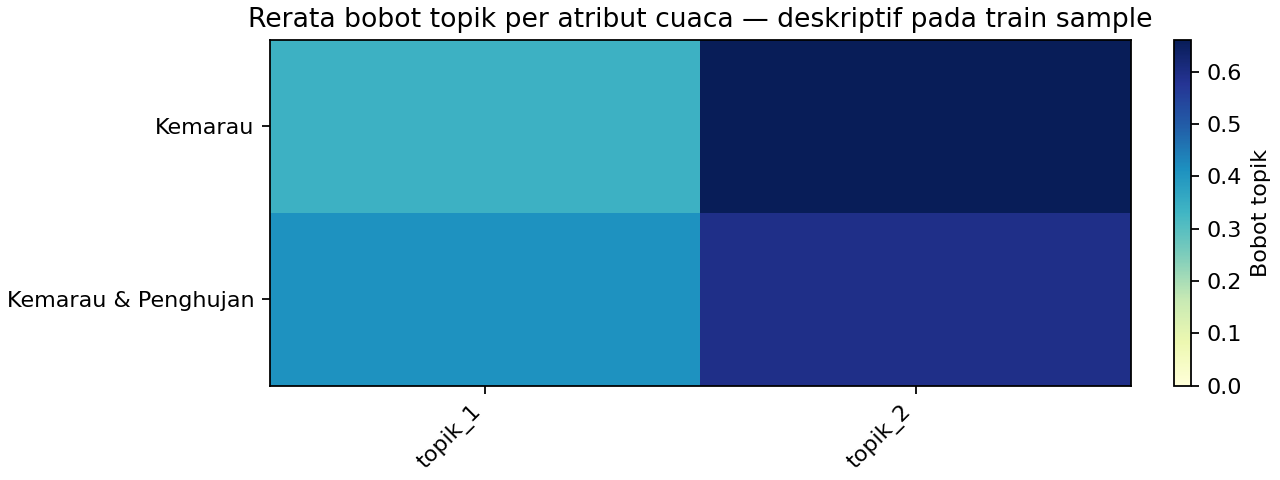

In [7]:
from wisata_madura.topics import TopicConfig, analyze_topics
from IPython.display import Image
from dataclasses import asdict

topic_config = TopicConfig(topic_counts=TOPIC_COUNTS, seeds=LDA_SEEDS,
                          max_iter=LDA_MAX_ITER, per_destination=LDA_REVIEWS_PER_DESTINATION)
topics, topic_tables, topic_audit = analyze_topics(split, OUTPUT_DIR, topic_config)
audit["lda"] = topic_audit
print("K terpilih:", topic_audit["selected_topics"])
display(topic_tables["pemilihan_topik"].round(4))
display(topic_tables["kualitas_topik"].round(4))
for filename in ("pemilihan_topik.png", "kata_utama_topik.png", "heatmap_topik_cuaca.png"):
    display(Image(filename=str(OUTPUT_DIR / filename)))

## 05B Baca contoh ulasan dan evaluasi fitur LDA

R03–R05: periksa kata dan ulasan yang topik dominannya cocok. Topik yang tidak dominan pada dokumen mana pun dapat tidak punya contoh. Nama aspek tidak diisi otomatis; gunakan `template_review_topik.csv` setelah membaca contoh.

Heatmap cuaca hanya deskriptif pada train sample dan ditimbang per destinasi. Perbedaan bobot bukan bukti perubahan antar-musim kunjungan. LDA + regresi logistik adalah klasifikasi atribut dari fitur topik; ini berbeda dari menilai coherence topik.

In [8]:
pd.set_option("display.max_colwidth", 160)
display(topic_tables["contoh_ulasan_topik"])
print("Review manual: baca contoh, isi nama/catatan pada template_review_topik.csv.")
predictions.update(run_lda_only(split, topics, seed=SEED))


,topik,bobot,id_destinasi,destinasi,teks_model,asal
0,topik_1,0.980291,43,Candi Ranjangbatu,candi bajang ratu situs candi hindu letak jl candi tikus no palem ton camat trowulan kabupaten mojokerto jawa timur candi milik sejarah kaya bagi bekas wila...,train_sample
1,topik_1,0.979661,100,Makam Sunandrajat,sunan drajat salah satu sunan sembilan sunan wali songo nama kecil raden qasim kemudian dapat gelar raden syarifudin sunan drajat kira lahir tahun masehi pu...,train_sample
2,topik_1,0.978788,176,Simpang Lima,monumen simpang lima gumul sebut monumen slg tugu slg bangun jadi ikon kabupaten diri bentuk bangun lengkung monumen slg mulai bangun tahun resmi tahun gaga...,train_sample
3,topik_1,0.978570,37,Candi Panataran,candi natar rupa salah satu destinasi wisata sejarah budaya kenal kabupaten blitar jawa timur letak desa natar camat nglegok candi ada km pusat kota blitar ...,train_sample
4,topik_1,0.977946,98,Mahavihara Mojopahit,maha vihara mojopahit agama budaya padu harmonimenjelajahi sudut jawa ungkap sejarah besar jawa tur unik rancang jiwa tualang kenal jawa lebih dekat sama sa...,train_sample
5,topik_2,0.983289,76,Hutan Pinus Selondo,tiket masuk cuma rp masuk kolam renang bayar tiket rp hutan pinus sejuk banyak gazebo istirahat banyak warung sekitar gazebo kolam renang lumayan bersih har...,train_sample
6,topik_2,0.983142,146,Pantai Kutang,pantai cukup indah jembatan warna warni jadi daya tarik fotografi lokasi mudah jangkau tiket masuk lokasi jangkau banyak warung makan santa dapat toilet umu...,train_sample
7,topik_2,0.981142,33,Bukit Jengkoang,kebun warga tempat viwe sangat sangat kagum tetap jaga bersih jangan jalan tengah kebun warga cukup jalan utama saran kesana bagus jam lebih terlalu silau c...,train_sample
8,topik_2,0.980202,5,Air Terjuntancakkembar,lokasi jauh jalan raya tempat sepi akses jalan sulit jalan banyak rusak rugi datang kesini tempat beneran rawat cuma toilet rusak saran buang air kesini tik...,train_sample
9,topik_2,0.979740,19,Air Terjun Toroan,air terjun cukup bagus akses mobil sangat mudah tepi jalan raya lintas utara madura tiket masuk ribu parkir mobim ribu musholla toilet bersih hati turun mwn...,train_sample


Review manual: baca contoh, isi nama/catatan pada template_review_topik.csv.


## 06 FastText dari train saja

R07: representasi subword FastText dipelajari dari train saja. Embedding dibekukan saat BiLSTM dilatih. Kata validation/test baru mendapat vektor subword dari model tersebut, tanpa melatih ulang pada validation/test. Panjang urutan, dimensi, dan epoch adalah pengaturan eksperimen; lihat metodologi.

In [9]:
if RUN_DEEP:
    from wisata_madura.neural import DeepConfig, fit_fasttext, run_bilstm_variants, plot_training_history
    deep_config = DeepConfig(seed=SEED, bilstm_epochs=MAX_BILSTM_EPOCHS,
                             patience=EARLY_STOPPING_PATIENCE)
    encoded = fit_fasttext(split, deep_config, output_dir=OUTPUT_DIR / "models")
    audit["deep_config"] = asdict(deep_config)
    print("Train:", encoded.train_tokens.shape, "Validation:", encoded.validation_tokens.shape)
    print("Embedding:", encoded.embeddings.shape)
else:
    print("FastText/BiLSTM tidak dijalankan pada run ini.")

Train: (47459, 64) Validation: (12473, 64)
Embedding: (45507, 80)


## 07 BiLSTM, validation loss, early stopping, dan checkpoint

R08–R12: dua varian mempertahankan arsitektur urutan, split, optimizer, dan anggaran epoch yang sama. Satu kepala softmax memprediksi setiap atribut (bukan sentimen multi-label).

Validation loss memakai bobot kelas dari train; tidak menggunakan test. Hentikan setelah beberapa epoch tanpa perbaikan, pulihkan checkpoint terbaik, kemudian prediksi test. Grafik memperlihatkan train/validation loss. R13: satu seed deep-learning belum mengukur variasi antar-run; tiga seed pada pencarian LDA tidak berarti BiLSTM sudah diuji tiga seed.

fasttext_bilstm | epoch 1/15 | train=1.5085 | validation=2.4253


fasttext_bilstm | epoch 2/15 | train=1.3824 | validation=2.4414


fasttext_bilstm | epoch 3/15 | train=1.3332 | validation=2.3374


fasttext_bilstm | epoch 4/15 | train=1.3001 | validation=2.2409


fasttext_bilstm | epoch 5/15 | train=1.2716 | validation=2.3810


fasttext_bilstm | epoch 6/15 | train=1.2456 | validation=2.2753


... (8 outputs left out)

fasttext_lda_bilstm | epoch 7/15 | train=1.2250 | validation=2.3817


Early stopping; best epoch=4


,model,epoch,train_loss,validation_loss,checkpoint_improved,device,validation_macro_f1_rekomendasi_cuaca,validation_macro_f1_wisata
0,fasttext_bilstm,1,1.508523,2.425313,True,cpu,0.608834,0.247296
1,fasttext_bilstm,2,1.382371,2.441424,False,cpu,0.607089,0.265226
2,fasttext_bilstm,3,1.333214,2.337411,True,cpu,0.610765,0.284692
3,fasttext_bilstm,4,1.300112,2.240896,True,cpu,0.610627,0.309409
4,fasttext_bilstm,5,1.271591,2.380953,False,cpu,0.608464,0.314910
5,fasttext_bilstm,6,1.245606,2.275283,False,cpu,0.625662,0.332690
6,fasttext_bilstm,7,1.223237,2.354123,False,cpu,0.607009,0.318874
7,fasttext_lda_bilstm,1,1.510099,2.454539,True,cpu,0.616040,0.235909
8,fasttext_lda_bilstm,2,1.379909,2.449113,True,cpu,0.615487,0.276583
9,fasttext_lda_bilstm,3,1.335084,2.374456,True,cpu,0.620707,0.300712


,model,best_epoch,best_validation_loss,epochs_executed,device
0,fasttext_bilstm,4,2.240896,7,cpu
1,fasttext_lda_bilstm,4,2.236057,7,cpu


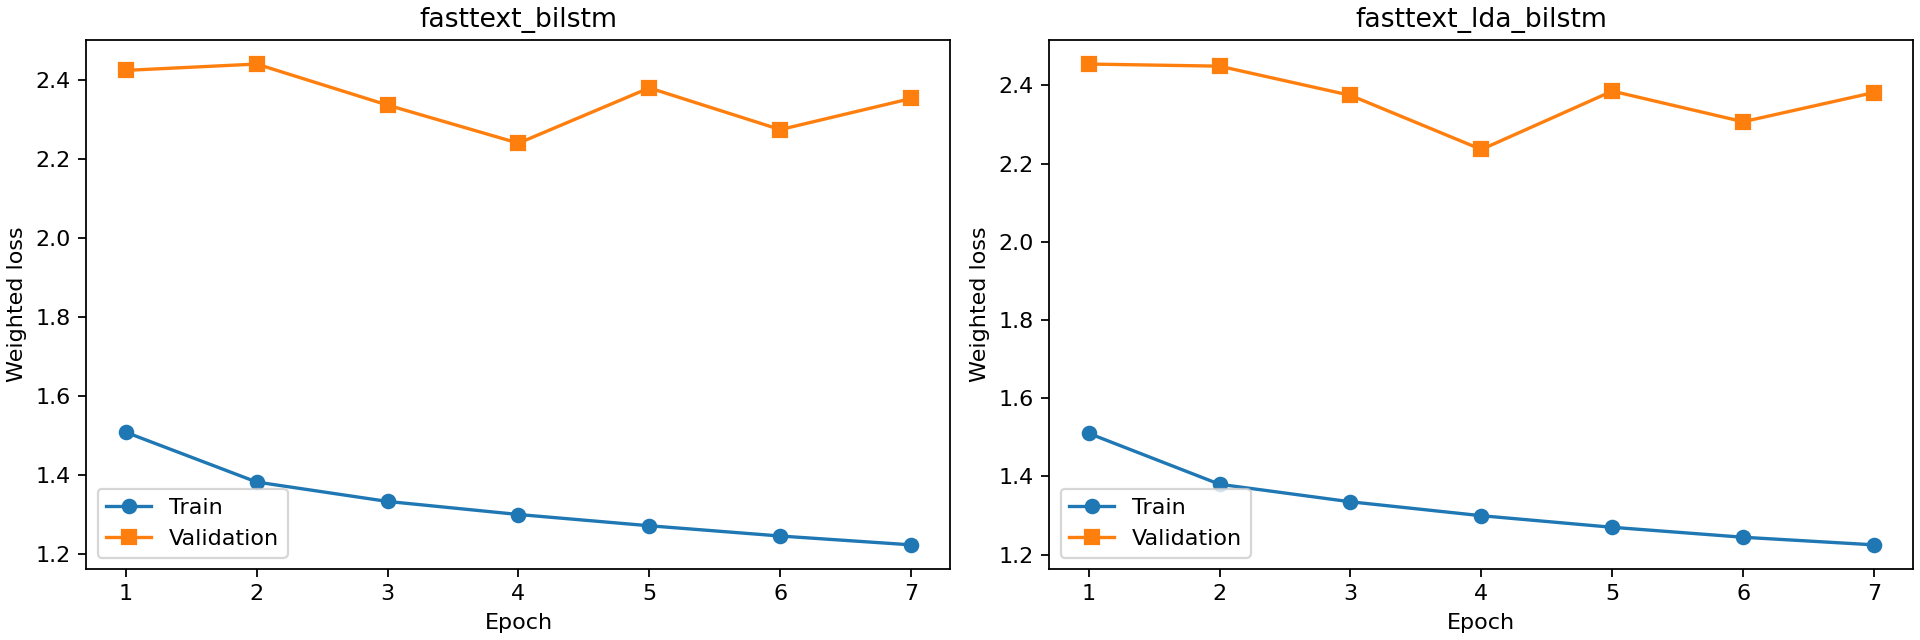

In [10]:
if RUN_DEEP:
    deep_predictions, training_history = run_bilstm_variants(
        split, topics, encoded, deep_config, output_dir=OUTPUT_DIR / "models")
    predictions.update(deep_predictions)
    training_history.to_csv(OUTPUT_DIR / "riwayat_bilstm.csv", index=False)
    plot_training_history(training_history, OUTPUT_DIR)
    display(training_history)
    display(pd.read_csv(OUTPUT_DIR / "models" / "checkpoint_bilstm.csv"))
    display(Image(filename=str(OUTPUT_DIR / "kurva_bilstm.png")))
else:
    print("Evaluasi berikut hanya untuk model yang benar-benar dijalankan.")

## 08 Evaluasi akhir pada test

R06, R13–R14: tampilkan accuracy, micro-F1, macro-F1, Hamming loss, serta hasil per kelas. Prediksi destinasi adalah suara terbanyak ulasan. Perbandingan fitur tidak menjamin LDA meningkatkan hasil.

Karena setiap atribut satu label per contoh, micro-F1 setara accuracy dan Hamming loss = 1 - accuracy. Jangan menganggap ketiganya bukti independen. Test tetap satu partisi 43 destinasi pada paket lengkap; kesimpulan stabil memerlukan evaluasi berulang terpisah.

,target,model,unit,accuracy,micro_f1,macro_f1,hamming_loss,n
1,rekomendasi_cuaca,mayoritas,destinasi,0.5581,0.5581,0.3582,0.4419,43
3,wisata,mayoritas,destinasi,0.2093,0.2093,0.0247,0.7907,43
5,rekomendasi_cuaca,tfidf_linear_svc,destinasi,0.5581,0.5581,0.5572,0.4419,43
7,wisata,tfidf_linear_svc,destinasi,0.7442,0.7442,0.5767,0.2558,43
9,rekomendasi_cuaca,lda_logreg,destinasi,0.5349,0.5349,0.5285,0.4651,43
11,wisata,lda_logreg,destinasi,0.2791,0.2791,0.0620,0.7209,43
13,rekomendasi_cuaca,fasttext_bilstm,destinasi,0.5814,0.5814,0.5812,0.4186,43
15,wisata,fasttext_bilstm,destinasi,0.6977,0.6977,0.5566,0.3023,43
17,rekomendasi_cuaca,fasttext_lda_bilstm,destinasi,0.5349,0.5349,0.5285,0.4651,43
19,wisata,fasttext_lda_bilstm,destinasi,0.7442,0.7442,0.5820,0.2558,43


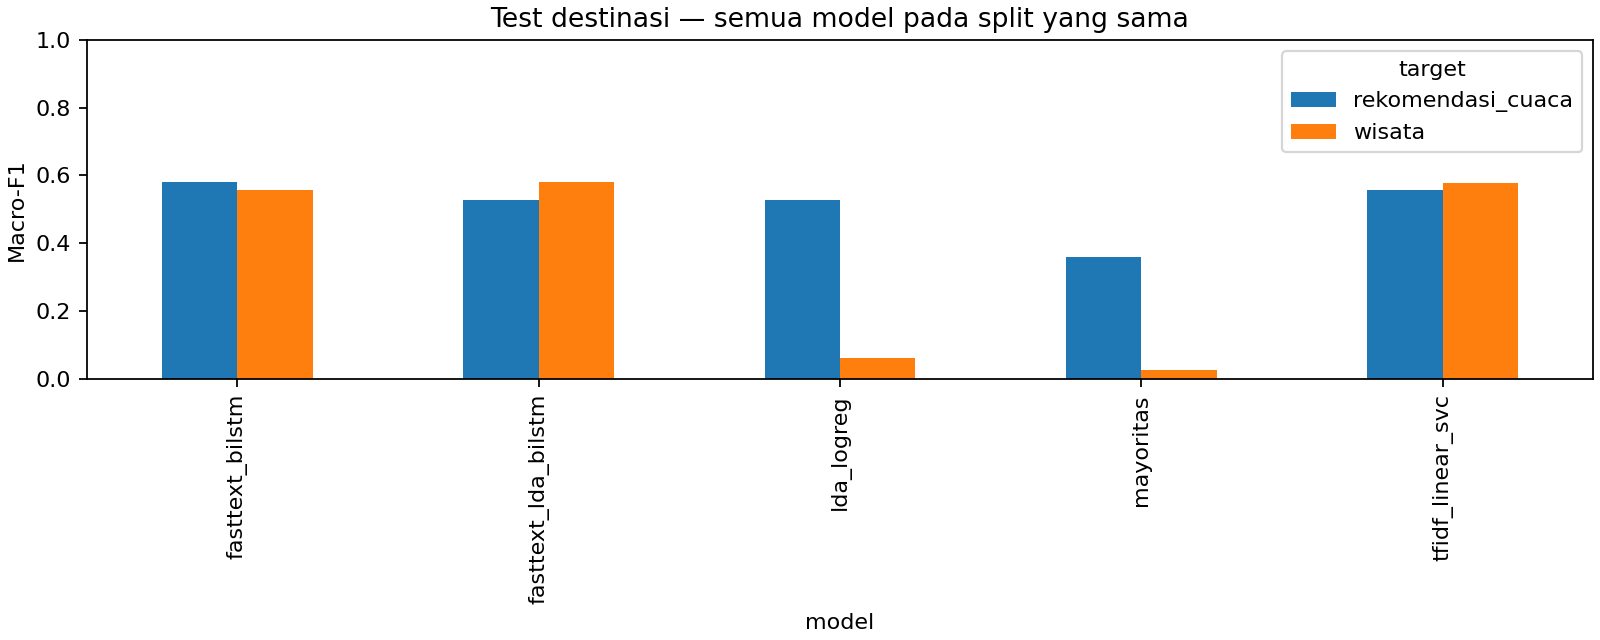

In [11]:
metrics, per_class = evaluate_classifiers(split.test, predictions)
display(metrics.loc[metrics["unit"].eq("destinasi")].round(4))
metrics.to_csv(OUTPUT_DIR / "metrik_klasifikasi.csv", index=False)
per_class.to_csv(OUTPUT_DIR / "metrik_per_kelas.csv", index=False)
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
metrics.loc[metrics.unit.eq("destinasi")].pivot(index="model", columns="target", values="macro_f1").plot.bar(ax=ax)
ax.set(ylabel="Macro-F1", title="Test destinasi — semua model pada split yang sama", ylim=(0, 1))
fig.savefig(OUTPUT_DIR / "perbandingan_model.png", dpi=160)
plt.close(fig)
display(Image(filename=str(OUTPUT_DIR / "perbandingan_model.png")))

## 09 Rekomendasikan destinasi dengan BGE

**Masukan:** preferensi, konteks Kemarau/Penghujan jika diketahui, dan ID kunjungan opsional. BGE-M3 memberi skor kemiripan semantik pada deskripsi destinasi. Atribut cuaca pada workbook menyaring kandidat sesuai pilihan pengguna. Modul memakai katalog yang tersedia sebagai tahap pemeringkatan. Keluaran klasifikasi dapat dipertimbangkan untuk katalog baru setelah modelnya tervalidasi.

Ubah preferensi dan musim di sel berikut. Peringkat contoh tidak digunakan sebagai penilaian relevansi. Isi `JUDGMENTS_PATH` dengan CSV relevansi independen berkolom `query_id,preferensi,musim,id_destinasi` untuk menghitung Precision@K dan Recall@K.

In [12]:
from wisata_madura.recommendation import BGERecommender, build_catalog, evaluate_recommendations

PREFERENSI = "Wisata alam dengan pemandangan yang cocok untuk keluarga"
MUSIM = "Penghujan"
RIWAYAT_IDS = []
K = 5

catalog = build_catalog(reviews)
print(f"{len(catalog)} destinasi dalam katalog dengan cakupan {geography['scope']}.")

if RUN_BGE:
    recommender = BGERecommender.from_pretrained(catalog)
    ranking = recommender.recommend(PREFERENSI, MUSIM, k=K, riwayat_ids=RIWAYAT_IDS)
    display(ranking)
    ranking.assign(cakupan=geography["scope"]).to_csv(OUTPUT_DIR / "contoh_rekomendasi.csv", index=False)
    if JUDGMENTS_PATH is not None:
        judgments = pd.read_csv(JUDGMENTS_PATH, dtype={"id_destinasi": str})
        ranking_metrics = evaluate_recommendations(recommender, judgments, k=K)
        display(ranking_metrics)
        display(ranking_metrics[["precision_at_k", "recall_at_k"]].mean())
        ranking_metrics.to_csv(OUTPUT_DIR / "metrik_rekomendasi.csv", index=False)
    else:
        print("Precision@K dan Recall@K memerlukan CSV penilaian relevansi independen.")
else:
    print("Katalog siap. Aktifkan RUN_BGE di bagian 00 untuk memeringkat destinasi.")

207 destinasi dalam katalog dengan cakupan workbook_complete_unverified.
Katalog siap. Aktifkan RUN_BGE di bagian 00 untuk memeringkat destinasi.


## 10 Simpan provenance, parameter, hasil, dan model

Seed, versi paket, commit/hash modul, konfigurasi LDA, split, serta checkpoint disimpan. Satu run satu folder. Berkas model hanya dimuat jika berasal dari run/sumber yang dipercaya.

Artefak baru: tabel pencarian, coherence per topik, kestabilan, bobot kata, contoh ulasan, template review, grafik, model/vectorizer LDA, dan (jika deep aktif) model FastText serta checkpoint BiLSTM.

Cakupan wilayah, asal label cuaca, anotasi sentimen, dan relevansi rekomendasi masih membutuhkan bukti. R01–R14 serta batas adaptasi implementasi ada di `docs/METODOLOGI_DAN_PAPER.md`.

In [13]:
packages = ["numpy", "pandas", "scikit-learn", "openpyxl", "matplotlib"]
if RUN_DEEP:
    packages += ["gensim", "torch"]
if RUN_BGE:
    packages += ["sentence-transformers"]

audit.update({
    "python": sys.version.split()[0],
    "pipeline_version": "2.0",
    "source_commit": source_commit,
    "source_module_sha256": source_hashes,
    "packages": {package: version(package) for package in packages},
    "run_deep": RUN_DEEP,
    "run_bge": RUN_BGE,
})
(OUTPUT_DIR / "audit_dataset.json").write_text(
    json.dumps(audit, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Keluaran:", OUTPUT_DIR.resolve())
print("\n".join(f.name for f in sorted(OUTPUT_DIR.iterdir()) if f.is_file()))

Keluaran: /workspace/crispy_recom_machine_system/hasil_wisata_madura/20261111-143703-377135
audit_dataset.json
audit_lda.json
bobot_kata_topik.csv
contoh_ulasan_topik.csv
distribusi_label.csv
distribusi_topik_dokumen_latih.csv
heatmap_topik_cuaca.png
id_partisi_test.csv
id_partisi_train.csv
id_partisi_validation.csv
kata_utama_topik.png
kualitas_topik.csv
kurva_bilstm.png
metrik_klasifikasi.csv
metrik_per_kelas.csv
model_lda.joblib
pemilihan_topik.csv
pemilihan_topik.png
pencarian_lda.csv
perbandingan_model.png
ringkasan_topik_per_label_cuaca.csv
riwayat_bilstm.csv
template_review_topik.csv
template_verifikasi_wilayah.csv
topik_lda.csv
